# Image segmentation

A foundational feild into images based models, where we pin point exact pixels into the image for segrigating objects into the main image, With U-NET architechture ( originally developed for medical images ), Now serves the fundamental approach for image segmentations.

### Project scope 

With this project is aimed for exploring deep learning with image segmentation, model is just toy example built with tools and strictly for academic exploration. Not tested nor medically aligned, its pure for exploration and learning

## 1. Breif into architechture

1. Encoder-Decoder structure : 
    >Encoder extracts feature from downsampling, decoder reconstructs the segmentation through up-sampling.

2. Skip-Connection : 
    >Connecting encoder to decoders for preventing loss due to downsamples about spatial information.

3. Contextual information : 
    >With contracting path for presize localization making it perticularly usefull with segmentation.

**Wonders in imaging**
+ Exceptional segmentation capabilities
+ Captures fine boundaries
+ Precise locations context


---

+ Below implementation have some serious problem with training
+ Concepts need to be learnt the whole way around the model does not work for now 

In [7]:
# Import cell
import os 

import numpy as np  
import pandas as pd 

# Image processing libraries
import cv2 
from PIL import Image

# Visualizations 
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

Total matched pairs found: 3933


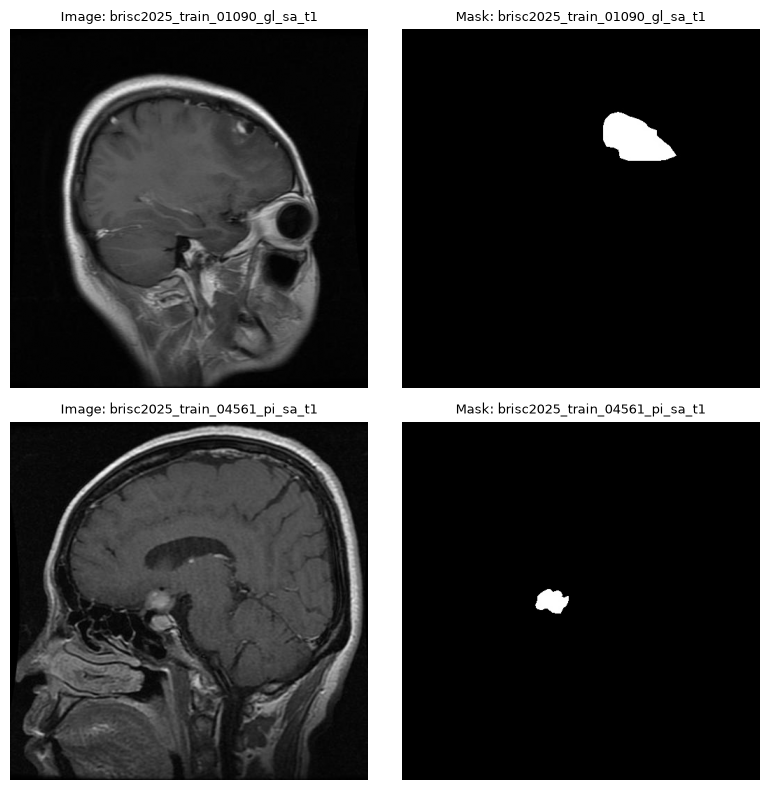

In [8]:
import os
import random
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

segmentation_df = pd.read_csv(
    "/home/madhav/workstation/Lab/experiment/data/BrainTumour/segmentation_task/train/segmentation_train.csv"
)


# 1. Extract the stem (filename WITHOUT extension, e.g., 'brisc2025_train_00296_gl_ax_t1')
def get_stem(path):
    filename = os.path.basename(path)
    stem, _ = os.path.splitext(filename)
    # Also strip '_mask' if your mask filenames end with it
    return stem.replace("_mask", "")


segmentation_df["stem"] = segmentation_df["image_path"].apply(get_stem)

# 2. Split and merge on the clean stem
images = segmentation_df[segmentation_df["label"] == "images"][
    ["stem", "image_path"]
]
masks = segmentation_df[segmentation_df["label"] == "masks"][
    ["stem", "image_path"]
]


# Merging the columns with common names with the two data frames
paired_df = pd.merge(
    images, masks, on="stem", suffixes=("_img", "_mask")
).reset_index(drop=True)
print(f"Total matched pairs found: {len(paired_df)}")

# 3. Safely cap num_samples so it never exceeds len(paired_df)
num_samples = min(2, len(paired_df))
random_indices = random.sample(range(len(paired_df)), num_samples)

width = 4
fig, axs = plt.subplots(
    nrows=num_samples,
    ncols=2,
    figsize=(width * 2, width * num_samples),
    squeeze=False,
)

for row, idx in enumerate(random_indices):
    img_path = paired_df.loc[idx, "image_path_img"]
    mask_path = paired_df.loc[idx, "image_path_mask"]
    stem = paired_df.loc[idx, "stem"]

    img = Image.open(img_path)
    mask = Image.open(mask_path)

    axs[row, 0].imshow(img, cmap="gray")
    axs[row, 0].set_title(f"Image: {stem}", fontsize=9)
    axs[row, 0].axis("off")

    axs[row, 1].imshow(mask, cmap="gray")
    axs[row, 1].set_title(f"Mask: {stem}", fontsize=9)
    axs[row, 1].axis("off")

plt.tight_layout()
plt.show()


In [9]:
# Deep learning setup
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# pytorch vision
import torchvision
from torchvision import models
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder

# data handling
from torch.utils.data import DataLoader, Dataset
from torch.optim import lr_scheduler

# Image augmentation
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [10]:
# Environement configurations

class Config:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    split_pc = 0.2

    learning_rate = 3e-2
    batch_size = 4
    epotch = 3

from pathlib import Path
ROOT_DIR = Path(
    '/home/madhav/workstation/Lab/experiment/data/BrainTumour/segmentation_task'
)

# Seed config for the libraries
seed = 123
np.random.seed(seed)
torch.manual_seed(seed)

In [11]:
# Dataset handler for the image dataset

class SegmentationDataset(Dataset):
    """ 
    Apply transformation to the image and its mask
    return the image and mask pair after transformation
    """
    def __init__(self, img_list, mask_list, transform=None):
        """ 
        initialize dataset with images and mask file name
        """ 
        self.img_list = img_list
        self.mask_list = mask_list
        self.transform = transform

    def __len__(self):
        return len(self.img_list)
    
    def __getitem__(self, index):
        """ 
        Geting a sample from the dataset
        fro processing
        """
        img_path = os.path.join('/home/madhav/workstation/Lab/experiment/data/BrainTumour/segmentation_task/train/images', self.img_list[index])
        mask_path = os.path.join('/home/madhav/workstation/Lab/experiment/data/BrainTumour/segmentation_task/train/images', self.mask_list[index])

        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        # Converting images to numpy for processing
        image = np.array(img)
        mask = np.array(mask)

        TARGET_SIZE = (256, 256)
        image = cv2.resize(image, TARGET_SIZE, interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, TARGET_SIZE, interpolation=cv2.INTER_NEAREST) # Use NEAREST for masks!


        # Transformation application
        augmentation = self.transform(image=image, mask=mask)
        img = augmentation['image']
        mask = augmentation['mask']

        # channel dimensions implemented here
        mask = mask.reshape(1, mask.shape[0], mask.shape[1])
        return img, mask

# Transformations definition
train_transform = A.Compose(
    [
        A.Resize(512, 512),
        A.Rotate(limmit=15, p=0.1),
        A.HorizontalFlip(p=0.5),
        A.Normalize(
            mean=(0,0,0),
            std=(1,1,1),
            max_pixel_value=255
        ),
        ToTensorV2()
    ]
)

test_transform = A.Compose(
    [
        A.Resize(512, 512),
        A.Normalize(
            mean=(0,0,0),
            std=(1,1,1),
            max_pixel_value=255
        ),
        ToTensorV2()
    ]
)

/tmp/ipykernel_106833/3905971739.py:52: UserWarning: Argument(s) 'limmit' are not valid for transform Rotate
  A.Rotate(limmit=15, p=0.1),


In [12]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as TF

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, features=[64, 128, 256, 512]):
        super(UNet, self).__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        for feature in features:
            self.downs.append(DoubleConv(in_channels, feature))
            in_channels = feature

        for feature in reversed(features):
            self.ups.append(
                nn.ConvTranspose2d(feature * 2, feature, kernel_size=2, stride=2)
            )
            self.ups.append(DoubleConv(feature * 2, feature))

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        
        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []

        # Run Encoder
        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        # Run Decoder with Skip Connections
        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x) # ConvTranspose2d
            skip_connection = skip_connections[idx // 2]

            # If input sizes don't match due to odd dimensions, resize them dynamically
            if x.shape != skip_connection.shape:
                x = TF.resize(x, size=skip_connection.shape[2:])

            concat_x = torch.cat((skip_connection, x), dim=1)
            x = self.ups[idx + 1](concat_x) # DoubleConv

        return self.final_conv(x)


def forward_check():
    # Simulate a single batch of RGB images sized 256x256
    x = torch.randn((1, 3, 256, 256))
    # Binary segmentation task (1 output channel)
    model = UNet(in_channels=3, out_channels=1)
    preds = model(x)
    
    print(f"Input shape: {x.shape}")
    print(f"Output shape: {preds.shape}")
    assert preds.shape == x.shape[:1] + (1,) + x.shape[2:], "Shape mismatch error!"

forward_check()

Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 256, 256])


In [ ]:
# Training Loop
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
# Assuming your U-Net model code is imported or defined here

# 1. Hyperparameters & Configuration
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LEARNING_RATE = 1e-4
BATCH_SIZE = 4
NUM_EPOCHS = 10

# 2. Setup Data Lists cleanly
images = list(paired_df.loc[:, 'image_path_img'])
masks = list(paired_df.loc[:, 'image_path_mask'])

test_size = int(len(images) * 0.2)
test_images, train_images = images[:test_size], images[test_size:]
test_masks, train_masks = masks[:test_size], masks[test_size:]

# 3. Datasets & Loaders
train_dataset = SegmentationDataset(train_images, train_masks, transform=train_transform)
valid_dataset = SegmentationDataset(test_images, test_masks, transform=test_transform)

train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_dataloader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 4. Instantiate Model and Loss Function
model = UNet(in_channels=3, out_channels=1).to(DEVICE)

loss_fn = nn.BCEWithLogitsLoss() 
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler()


def train_fn(loader, model, optimizer, loss_fn, scaler):
    """Runs one epoch of training."""
    model.train()
    running_loss = 0.0
    
    for batch_idx, (data, targets) in enumerate(loader):
        data = data.to(device=DEVICE)
        
        # Ensure target shape matches prediction shape [B, 1, H, W] and is a float for BCE
        targets = targets.float().unsqueeze(1).to(device=DEVICE) if len(targets.shape) == 3 else targets.float().to(device=DEVICE)

        # Forward pass (with Mixed Precision for faster training if on GPU)
        with torch.amp.autocast(device_type=DEVICE):
            predictions = model(data)
            loss = loss_fn(predictions, targets)

        # Backward pass
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Track metrics
        running_loss += loss.item()
        
        if batch_idx % 10 == 0:
            print(f"Batch [{batch_idx}/{len(loader)}] | Loss: {loss.item():.4f}")
            
    epoch_loss = running_loss / len(loader)
    print(f"==> Epoch Training Loss: {epoch_loss:.4f}")



In [15]:
# Run this cell to completely overwrite the broken weights
model = UNet(in_channels=3, out_channels=1).to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.BCEWithLogitsLoss()
scaler = torch.amp.GradScaler()


In [16]:
# 2. Instantiate Model, Loss Function, and Optimizer
model = UNet(in_channels=3, out_channels=1).to(DEVICE)

# Since out_channels=1, we use BCEWithLogitsLoss (expects raw logits, no Sigmoid in forward pass)
loss_fn = nn.BCEWithLogitsLoss() 
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Gradient scaler for mixed-precision training
scaler = torch.amp.GradScaler()

print(f"Starting training on device: {DEVICE}")

# 4. Core Training Loop
for epoch in range(NUM_EPOCHS):
    print(f"\n--- Epoch {epoch+1}/{NUM_EPOCHS} ---")
    
    train_fn(train_dataloader, model, optimizer, loss_fn, scaler)
    
    # 5. Optional: Save Checkpoint
    checkpoint = {"state_dict": model.state_dict(), "optimizer": optimizer.state_dict()}
    torch.save(checkpoint, f"my_unet_epoch_{epoch+1}.pth")


Starting training on device: cuda

--- Epoch 1/10 ---
Batch [0/787] | Loss: -0.2710
Batch [10/787] | Loss: -10.5222
Batch [20/787] | Loss: -8.9980
Batch [30/787] | Loss: -45.4298
Batch [40/787] | Loss: -58.2501
Batch [50/787] | Loss: -21.5045
Batch [60/787] | Loss: -36.8445
Batch [70/787] | Loss: -47.9822


KeyboardInterrupt: 